In [1]:
# Import required libraries 
import tensorflow as tf 
import matplotlib.pyplot as plt 
from tensorflow import keras 
from tensorflow.keras import layers 

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data() 

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2233s 13us/step


In [3]:
# Display dataset information 
print("Training images shape:", x_train.shape) 
print("Testing images shape:", x_test.shape) 

Training images shape: (50000, 32, 32, 3)
Testing images shape: (10000, 32, 32, 3)


In [4]:
# Normalize pixel values between 0 and 1 
x_train = x_train.astype("float32") / 255.0 
x_test = x_test.astype("float32") / 255.0 

In [5]:
# Define class names 
class_names = [ 
    "Airplane", "Automobile", "Bird", "Cat", "Deer", 
    "Dog", "Frog", "Horse", "Ship", "Truck" 
] 

In [6]:
 
# -------------------------------------------------- 
# Stage B: Defining the Model's Architecture 
# -------------------------------------------------- 
 
model = keras.Sequential([ 
    layers.Input(shape=(32, 32, 3)), 
    layers.Conv2D(32, (3, 3), activation="relu"), 
    layers.MaxPooling2D((2, 2)), 
    layers.Conv2D(64, (3, 3), activation="relu"), 
    layers.MaxPooling2D((2, 2)), 
    layers.Flatten(), 
    layers.Dense(128, activation="relu"), 
    layers.Dense(10, activation="softmax") 
]) 

In [7]:
# Display model architecture 
model.summary() 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compile the model 
model.compile( 
optimizer="adam", 
loss="sparse_categorical_crossentropy", 
metrics=["accuracy"] 
) 

In [9]:
# -------------------------------------------------- 
# Stage C: Training the Model 
# -------------------------------------------------- 
history = model.fit( 
x_train, 
y_train, 
epochs=10, 
batch_size=64, 
validation_split=0.1 
) 

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 50s 66ms/step - accuracy: 0.4680 - loss: 1.4792 - val_accuracy: 0.5558 - val_loss: 1.2441
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 56ms/step - accuracy: 0.6017 - loss: 1.1331 - val_accuracy: 0.6262 - val_loss: 1.0662
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 69ms/step - accuracy: 0.6533 - loss: 0.9922 - val_accuracy: 0.6370 - val_loss: 1.0378
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 64ms/step - accuracy: 0.6853 - loss: 0.9027 - val_accuracy: 0.6796 - val_loss: 0.9294
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 44s 63ms/step - accuracy: 0.7106 - loss: 0.8310 - val_accuracy: 0.6860 - val_loss: 0.9163
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 47s 67ms/step - accuracy: 0.7329 - loss: 0.7677 - val_accuracy: 0.6980 - val_loss: 0.8857
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 64ms/step - accuracy: 0.7548 - loss: 0.7040 - val_accuracy: 0.6990 - val_loss: 0.8828
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 47s 66ms/step - accuracy: 0.7733 - loss: 0.6484 - 

In [10]:
# -------------------------------------------------- 
# Stage D: Estimating the Model's Performance 
# -------------------------------------------------- 
test_loss, test_accuracy = model.evaluate( 
x_test, y_test, verbose=2 
) 
print("\nTest Loss:", test_loss) 
print("Test Accuracy:", test_accuracy * 100, "%") 

313/313 - 4s - 12ms/step - accuracy: 0.6875 - loss: 0.9851

Test Loss: 0.9851080179214478
Test Accuracy: 68.75 %


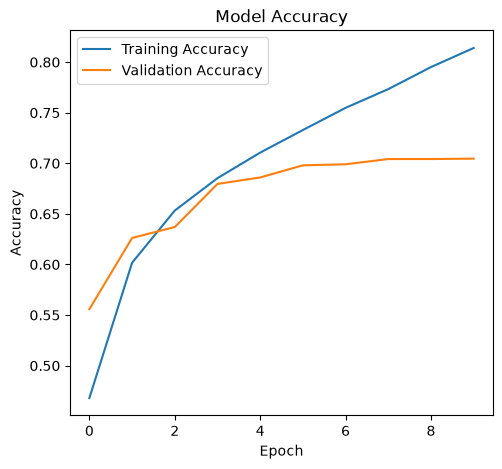

In [11]:
# Plot training and validation accuracy 
plt.figure(figsize=(12, 5)) 
plt.subplot(1, 2, 1) 
plt.plot(history.history["accuracy"], label="Training Accuracy") 
plt.plot(history.history["val_accuracy"], label="Validation Accuracy") 
plt.title("Model Accuracy") 
plt.xlabel("Epoch") 
plt.ylabel("Accuracy") 
plt.legend() 

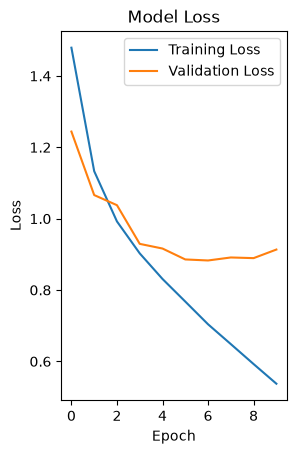

In [12]:
# Plot training and validation loss 
plt.subplot(1, 2, 2) 
plt.plot(history.history["loss"], label="Training Loss") 
plt.plot(history.history["val_loss"], label="Validation Loss") 
plt.title("Model Loss") 
plt.xlabel("Epoch") 
plt.ylabel("Loss") 
plt.legend() 

In [13]:
plt.tight_layout() 
plt.show() 

<Figure size 640x480 with 0 Axes>

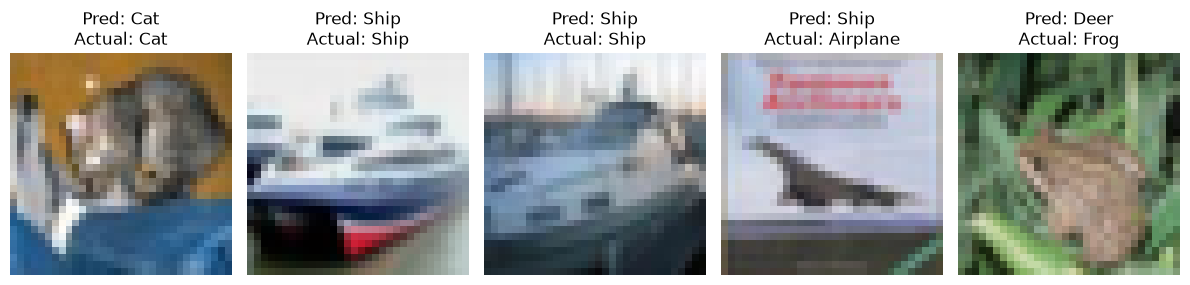

In [15]:
# Display predictions for sample test images 
predictions = model.predict(x_test[:5], verbose=0) 
plt.figure(figsize=(12, 3)) 
for i in range(5): 
    plt.subplot(1, 5, i + 1) 
    plt.imshow(x_test[i]) 
    predicted_class = class_names[predictions[i].argmax()] 
    actual_class = class_names[int(y_test[i][0])] 
    plt.title(f"Pred: {predicted_class}\nActual: {actual_class}") 
    plt.axis("off") 
plt.tight_layout() 
plt.show() 